# Practical No. 05 — Text-to-Image Generation Using Stable Diffusion

**Student:** Tanishka Vishnu Tapkir ·

**PRN:** 202401110071·

**Batch:** A3

**Library:** Hugging Face Diffusers ·

**Pretrained model:** `segmind/tiny-sd`





## 1. Introduction and Pipeline Components

Stable Diffusion is a text-to-image generative model. It starts from a noisy latent representation and progressively denoises it while conditioning the process on the text prompt.

| Component | Role |
|---|---|
| **Tokenizer + text encoder** | Converts the prompt into text embeddings used to condition generation. |
| **U-Net** | Predicts the noise in the latent representation at each denoising step. |
| **Scheduler** | Determines the denoising updates and step sequence. |
| **VAE** | Decodes the final latent representation into an RGB image. |

**Pipeline:** prompt → tokenization/text embeddings → noisy latent → repeated U-Net prediction and scheduler updates → denoised latent → VAE decoder → image.

### 1.1 Install required libraries


In [1]:
!pip -q install --upgrade diffusers transformers accelerate safetensors matplotlib

### 1.2 Select the runtime and load imports


In [2]:
import time
import torch
import matplotlib.pyplot as plt
from IPython.display import display
from diffusers import DiffusionPipeline

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32

print("Device:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


## 2. Loading the Pretrained Model




In [3]:
MODEL_ID = "segmind/tiny-sd"

pipe = DiffusionPipeline.from_pretrained(
    MODEL_ID,
    torch_dtype=DTYPE
)
pipe = pipe.to(DEVICE)
pipe.set_progress_bar_config(disable=True)

print("Loaded model:", MODEL_ID)
print("Pipeline:", type(pipe).__name__)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/584 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Loaded model: segmind/tiny-sd
Pipeline: StableDiffusionPipeline


### 2.1 Identify the main pipeline modules

In [4]:
print("Tokenizer:", type(pipe.tokenizer).__name__)
print("Text encoder:", type(pipe.text_encoder).__name__)
print("U-Net:", type(pipe.unet).__name__)
print("Scheduler:", type(pipe.scheduler).__name__)
print("VAE:", type(pipe.vae).__name__)

Tokenizer: CLIPTokenizer
Text encoder: CLIPTextModel
U-Net: UNet2DConditionModel
Scheduler: DPMSolverMultistepScheduler
VAE: AutoencoderKL


## 3. Text-to-Image Generation


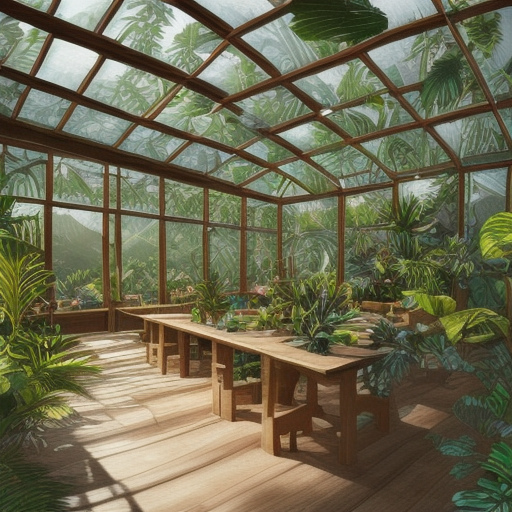

Baseline generation time: 5.38 seconds


In [5]:
BOTANICAL_PROMPT = (
    "A glass-roof botanical research station in a misty mountain valley, "
    "lush tropical plants, wooden research tables, soft morning sunlight, "
    "detailed digital illustration"
)

start = time.time()
baseline_image = pipe(
    prompt=BOTANICAL_PROMPT,
    num_inference_steps=25,
    guidance_scale=7.5
).images[0]
baseline_seconds = time.time() - start

display(baseline_image)
print(f"Baseline generation time: {baseline_seconds:.2f} seconds")
baseline_image.save("baseline_botanical_station.png")

## 4. Helper Function for Image Generation

The helper function accepts the prompt, inference steps, guidance scale, seed, and optional negative prompt. A fixed seed supports more controlled comparisons. The same seed does not guarantee identical results across every scheduler or software/hardware configuration.

In [6]:
SEED = 1234

def generate_image(
    prompt,
    steps=25,
    guidance=7.5,
    seed=SEED,
    negative_prompt=None,
    show=True
):
    generator = torch.Generator(device=DEVICE).manual_seed(seed)
    start_time = time.time()

    output = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        num_inference_steps=steps,
        guidance_scale=guidance,
        generator=generator
    )

    image = output.images[0]
    elapsed = time.time() - start_time

    if show:
        display(image)
    return image, elapsed

## 5. Experiment 1 — Effect of Inference Steps

Keep the prompt and guidance scale fixed, and compare **5, 10, 20, and 35** inference steps. More steps can allow additional refinement, but generation takes longer and improvements may diminish.

In [7]:
STEP_VALUES = [5, 10, 20, 35]
step_results = []

for steps in STEP_VALUES:
    print(f"\nInference steps = {steps}")
    image, seconds = generate_image(
        BOTANICAL_PROMPT,
        steps=steps,
        guidance=7.5,
        seed=SEED,
        show=False
    )
    step_results.append({"steps": steps, "seconds": seconds, "image": image})
    print(f"Time: {seconds:.2f} seconds")


Inference steps = 5
Time: 0.61 seconds

Inference steps = 10
Time: 0.99 seconds

Inference steps = 20
Time: 1.78 seconds

Inference steps = 35
Time: 2.96 seconds


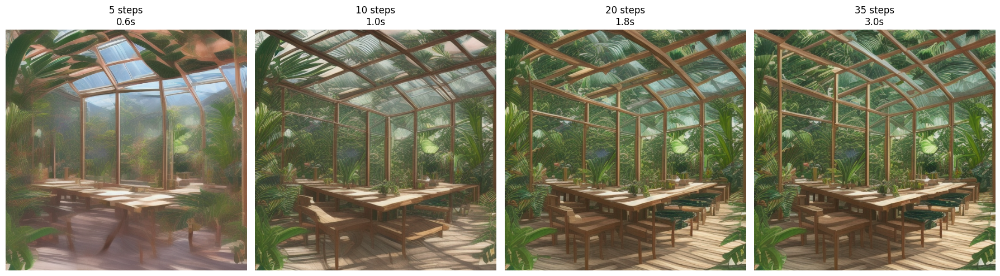

Inference-step timing summary
 5 steps: 0.61 seconds
10 steps: 0.99 seconds
20 steps: 1.78 seconds
35 steps: 2.96 seconds


In [8]:
fig, axes = plt.subplots(1, len(step_results), figsize=(18, 5))
for ax, result in zip(axes, step_results):
    ax.imshow(result["image"])
    ax.set_title(f'{result["steps"]} steps\n{result["seconds"]:.1f}s')
    ax.axis("off")
plt.tight_layout()
plt.show()

print("Inference-step timing summary")
for result in step_results:
    print(f'{result["steps"]:>2} steps: {result["seconds"]:.2f} seconds')

## 6. Experiment 2 — Effect of Guidance Scale


In [9]:
GUIDANCE_VALUES = [1, 4, 7.5, 11, 15]
GUIDANCE_PROMPT = (
    "An underwater library inside a transparent ocean dome, curved bookshelves, "
    "glowing jellyfish outside the glass, turquoise blue lighting, imaginative concept art"
)
guidance_results = []

for scale in GUIDANCE_VALUES:
    print(f"\nGuidance scale = {scale}")
    image, seconds = generate_image(
        GUIDANCE_PROMPT,
        steps=25,
        guidance=scale,
        seed=SEED,
        show=False
    )
    guidance_results.append({"guidance": scale, "seconds": seconds, "image": image})
    print(f"Time: {seconds:.2f} seconds")


Guidance scale = 1
Time: 1.53 seconds

Guidance scale = 4
Time: 2.20 seconds

Guidance scale = 7.5
Time: 2.21 seconds

Guidance scale = 11
Time: 2.21 seconds

Guidance scale = 15
Time: 2.22 seconds


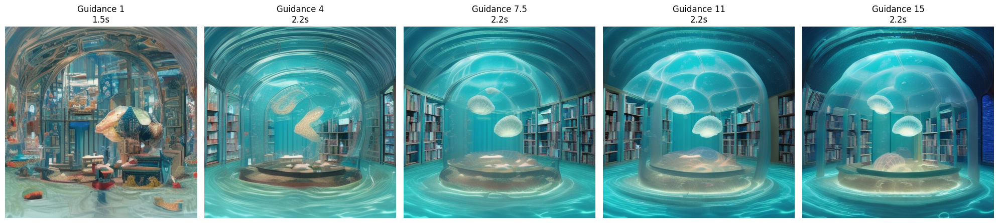

In [10]:
fig, axes = plt.subplots(1, len(guidance_results), figsize=(20, 5))
for ax, result in zip(axes, guidance_results):
    ax.imshow(result["image"])
    ax.set_title(f'Guidance {result["guidance"]}\n{result["seconds"]:.1f}s')
    ax.axis("off")
plt.tight_layout()
plt.show()

## 7. Experiment 3 — Prompt Variations

Use a fixed 25 inference steps and guidance scale 7.5. These distinct prompt themes show how subject and descriptive language change the output:
- Botanical research station
- Underwater library
- Miniature railway station inside a tree

In [11]:
PROMPT_VARIATIONS = {
    "Botanical research station": (
        "A glass-roof botanical research station in a misty mountain valley, "
        "tropical leaves, research tables, soft morning light, digital illustration"
    ),
    "Underwater library": (
        "An underwater library inside a transparent ocean dome, curved bookshelves, "
        "glowing jellyfish beyond the glass, turquoise light, dreamlike concept art"
    ),
    "Miniature railway station inside a tree": (
        "A tiny railway station built inside the hollow trunk of an ancient tree, "
        "miniature train, lanterns, moss and fireflies, whimsical storybook illustration"
    )
}
prompt_results = []

for theme, prompt_text in PROMPT_VARIATIONS.items():
    print("\nPrompt:", theme)
    image, seconds = generate_image(
        prompt_text, steps=25, guidance=7.5, seed=SEED, show=False
    )
    prompt_results.append({"theme": theme, "seconds": seconds, "image": image})
    print(f"Time: {seconds:.2f} seconds")


Prompt: Botanical research station
Time: 2.24 seconds

Prompt: Underwater library
Time: 2.24 seconds

Prompt: Miniature railway station inside a tree
Time: 2.26 seconds


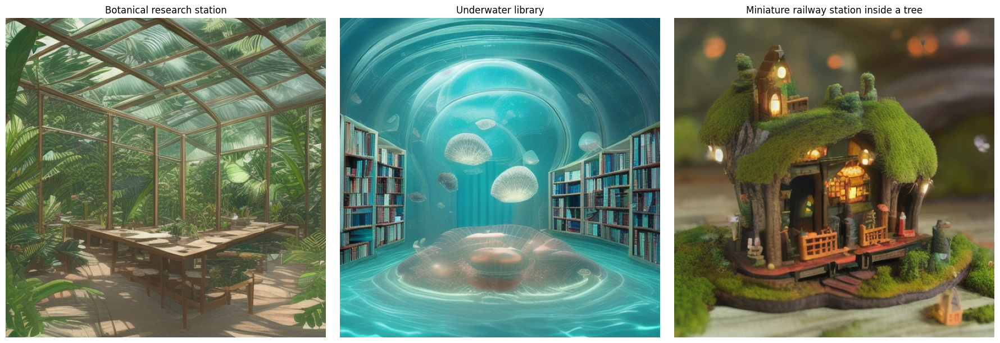

In [12]:
fig, axes = plt.subplots(1, len(prompt_results), figsize=(18, 6))
for ax, result in zip(axes, prompt_results):
    ax.imshow(result["image"])
    ax.set_title(result["theme"])
    ax.axis("off")
plt.tight_layout()
plt.show()

## 8. Experiment 4 — Prompt Engineering and Negative Prompts

A structured prompt can include the subject, setting, objects, lighting, and style. A negative prompt asks the model to avoid unwanted features; it can influence the output but does not guarantee their complete removal.

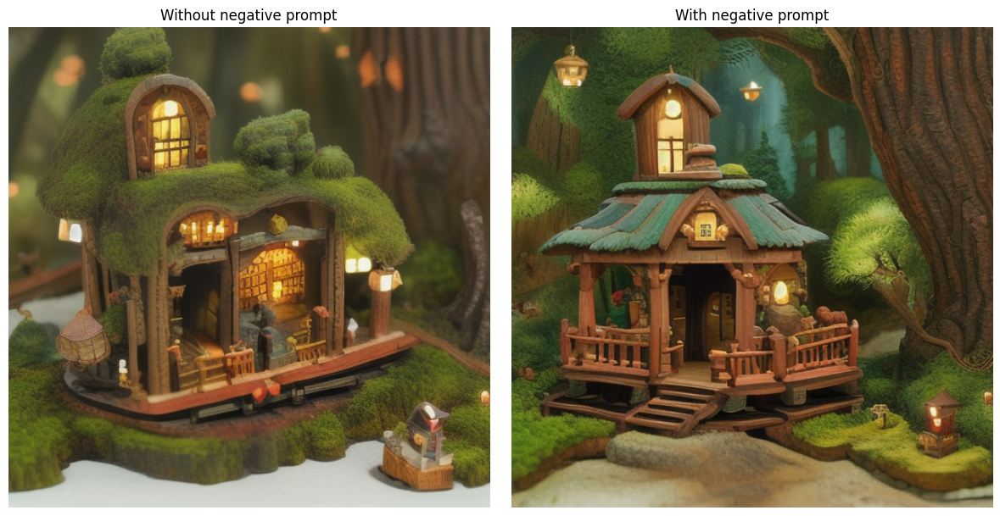

Without negative prompt: 2.28s
With negative prompt: 2.31s


In [13]:
TREE_PROMPT = (
    "A miniature railway station built inside the hollow trunk of an ancient tree, "
    "tiny train, wooden platform, warm lanterns, moss, fireflies, "
    "detailed whimsical storybook illustration"
)
NEGATIVE_PROMPT = (
    "blurry, low quality, distorted, malformed objects, duplicate objects, "
    "unreadable text, watermark"
)

image_without_negative, time_without_negative = generate_image(
    TREE_PROMPT,
    steps=25,
    guidance=7.5,
    seed=SEED,
    negative_prompt=None,
    show=False
)
image_with_negative, time_with_negative = generate_image(
    TREE_PROMPT,
    steps=25,
    guidance=7.5,
    seed=SEED,
    negative_prompt=NEGATIVE_PROMPT,
    show=False
)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(image_without_negative)
axes[0].set_title("Without negative prompt")
axes[0].axis("off")
axes[1].imshow(image_with_negative)
axes[1].set_title("With negative prompt")
axes[1].axis("off")
plt.tight_layout()
plt.show()

print(f"Without negative prompt: {time_without_negative:.2f}s")
print(f"With negative prompt: {time_with_negative:.2f}s")

## 9. Experiment 5 — Sampling Method (Scheduler) Comparison


In [14]:
from diffusers import (
    PNDMScheduler,
    DDIMScheduler,
    EulerDiscreteScheduler,
    EulerAncestralDiscreteScheduler,
    DPMSolverMultistepScheduler
)

SCHEDULER_CLASSES = {
    "PNDM": PNDMScheduler,
    "DDIM": DDIMScheduler,
    "Euler": EulerDiscreteScheduler,
    "Euler Ancestral": EulerAncestralDiscreteScheduler,
    "DPM-Solver": DPMSolverMultistepScheduler
}

SCHEDULER_PROMPT = (
    "A glass-roof botanical research station in a misty mountain valley, "
    "tropical plants, warm morning light, detailed digital illustration"
)

original_scheduler = pipe.scheduler
original_config = original_scheduler.config
scheduler_results = []

for name, scheduler_class in SCHEDULER_CLASSES.items():
    try:
        pipe.scheduler = scheduler_class.from_config(original_config)
        print(f"\nRunning scheduler: {name}")

        image, seconds = generate_image(
            SCHEDULER_PROMPT,
            steps=25,
            guidance=7.5,
            seed=SEED,
            show=False
        )
        scheduler_results.append({
            "name": name,
            "seconds": seconds,
            "image": image
        })
        print(f"Completed in {seconds:.2f} seconds")

    except Exception as error:
        print(f"Skipped {name}: {type(error).__name__}: {str(error)[:250]}")

# Restore the original scheduler after the comparison
pipe.scheduler = original_scheduler


Running scheduler: PNDM
Completed in 3.20 seconds

Running scheduler: DDIM
Completed in 2.33 seconds

Running scheduler: Euler
Completed in 2.33 seconds

Running scheduler: Euler Ancestral
Completed in 2.35 seconds

Running scheduler: DPM-Solver
Completed in 2.37 seconds


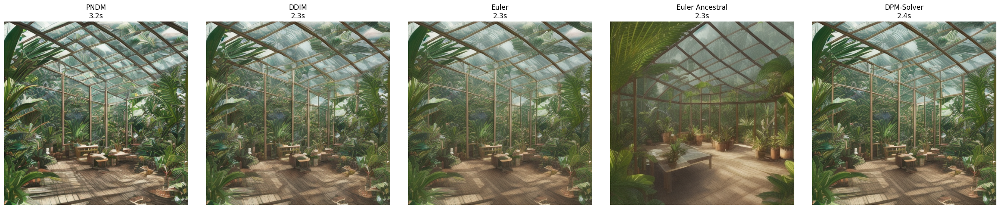

Scheduler timing summary
PNDM: 3.20 seconds
DDIM: 2.33 seconds
Euler: 2.33 seconds
Euler Ancestral: 2.35 seconds
DPM-Solver: 2.37 seconds


In [15]:
if scheduler_results:
    n = len(scheduler_results)
    fig, axes = plt.subplots(1, n, figsize=(5 * n, 5))
    if n == 1:
        axes = [axes]

    for ax, result in zip(axes, scheduler_results):
        ax.imshow(result["image"])
        ax.set_title(f'{result["name"]}\n{result["seconds"]:.1f}s')
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    print("Scheduler timing summary")
    for result in scheduler_results:
        print(f'{result["name"]}: {result["seconds"]:.2f} seconds')
else:
    print("No scheduler completed successfully; review the errors above.")

## 10. Conclusion

Stable Diffusion generates images by iteratively denoising a latent representation conditioned on text. The text encoder creates prompt embeddings, the U-Net predicts noise, the scheduler determines denoising updates, and the VAE decodes the final latent into an image.

The experiments study how inference steps, guidance scale, prompt design, negative prompts, and scheduler choice affect the generated output. Complete your report with the images and timing measurements from this notebook's actual execution.
